## Load the seaborn diamonds data set into a Pandas DataFrame
Load here means it comes from seaborn and not a file

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
#HAD TO MAKE SURE I HAD IMPORTED THE CORRECT LIBRARIES
#df is a dataframe containing the diamonds dataset
#pandas dataframe is a similar to an Excel spreadsheet or SQL table, where data is organized in rows and columns
df = sns.load_dataset('diamonds')

#To confirm it loaded correctly, we can check the first few rows using the head() method
df.head()

#to see the first 3 rows, use
df.head(3)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31


# What's the total number of rows and columns present in the entire data set

In [3]:
#total rows and columns
#this one is a tuple, (rows, columns)
df.shape
#total number of rows
#total number of rows out of the tuple, using index 0
#df.shape[0]
#total number of columns
#df.shape[1]


(53940, 10)

# What's the number of missing or null values in each column, Find out

In [4]:
df.isna().head()
#isna() checks for missing values in the dataframe, and returns  True for missing values and False for non-missing values. 
# By using head(), we can see the first few rows of this 

#We want to know all missing values in each column from begining to end
#sum() will add up all the True values (which are treated as 1) in each column,
#If there exists any missing value in a column, the sum will be greater than 0, otherwise it will be 0
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [5]:
#Identity categorical variables
#The 'cut', 'color', and 'clarity' columns are categorical variables that represent the quality of the diamonds.
#The 'cut' column describes the quality of the cut of the diamond, with categories: 'Fair', 'Good', 'Very Good', 'Premium', and 'Ideal'.
#The 'color' column represents the color grade of the diamond, with categories ranging from 'D' (colorless) to 'J' (near colorless).
#The 'clarity' column indicates the clarity grade of the diamond, with categories such as 'I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', and 'IF'.

df.dtypes 
#shows float64 for numeric columns
#shows category for categorical columns and proofs that the three categorical columns I mentioned were indeed correct.
categorical_features = ['cut', 'color', 'clarity']


In [6]:
#Calculate and show the descriptive statistics for the categorical variables
df[categorical_features].describe() 
#describe() gives a summary of the categorical variables, including the count of non-missing values, the number of unique categories, the most frequent category (top), and the frequency of the most frequent category (freq).

,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


Identify the unique labels present in each categorical feature save them in a sorted list, cut_labels. Sorted list,but alphabetically might be challenging since the ratings and their firs letter might not be the same and change things around. Sorted made me think of alphabetical order, but for these categorical features, alphabetical sorting wouldn't actually reflect anything meaningful — for example, sorting cut alphabetically would give "Fair, Good, Ideal, Premium, Very Good," which doesn't represent quality very well. Instead, the labels need to be sorted by their rank order, from best to worst.

In [7]:
#to see what answers exist in the 'cut' column, we can use the unique() method
df['cut'].unique()



['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, str): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

In [8]:
#to see what answesr exist in the 'color' column and what comes back we will use unique() method again
df['color'].unique()

#the answers in the output are the actual order they appear in the dataset and not in alphabetical order. 
#the second line says:Categories (7, str), which means/or is saying there are 7 categories and are sorted and are from best to worst
#this is an interesting find since the provided table says that best to worst is D,E,F,G,H,I,J and that is what showed up in the second line of the output.

['E', 'I', 'J', 'H', 'F', 'G', 'D']
Categories (7, str): ['D', 'E', 'F', 'G', 'H', 'I', 'J']

In [9]:
#to see the answers that exist in the 'clarity' column, we can use unique() method again
df['clarity'].unique()

['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Categories (8, str): ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']

In [10]:
#list for "cut" column
cut_labels = ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

#list for "color" column
color_labels = ['D', 'E', 'F', 'G', 'H', 'I', 'J']

#list for the "clarity" column
clarity_labels = ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']



# Construct a histogram for each categorical feature (cut, color, clarity). It matters if the data is categorical or not. Histograms required numerical data (prices, heights, ages, scores) 

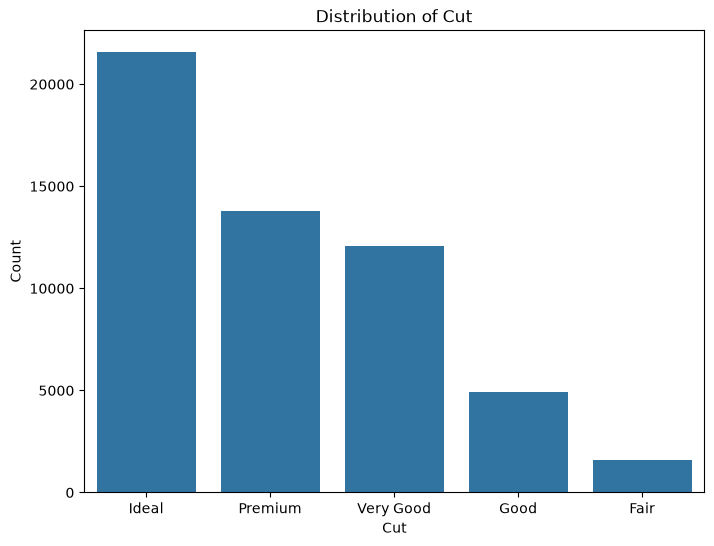

In [11]:

#histogram for "cut" column
#there's sns.countplot() for categorical variables, which shows the count of each category in the cut column.
#and there's sns.histplot() for numeric variables. For "cut" column, since its categorical, countplot seems more appropriate.

plt.figure(figsize=(8, 6))  #size of the plot
sns.countplot(x='cut', data=df, order=cut_labels)  #using order=cut_labels to ensure answers/categories are displayed in the correct order
plt.title('Distribution of Cut')  #title of the plot
plt.xlabel('Cut')  #label for the x-axis
plt.ylabel('Count')  #label for the y-axis
plt.show()  #display the plot

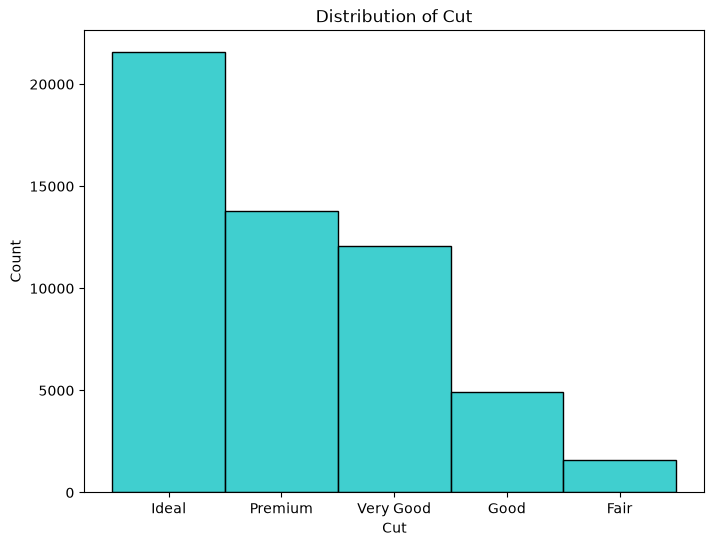

In [12]:
#If the "cut" column was interpreted using histplot()
#It seems that they pictures both look the same and both show the correct order from best to worst
plt.figure(figsize=(8, 6))  #size of the plot
sns.histplot(x='cut', data=df, color='c', discrete=True)
plt.title('Distribution of Cut')  #title of the plot
plt.xlabel('Cut')  #label for the x-axis
plt.ylabel('Count')  #label for the y-axis
plt.show()  #display the plot

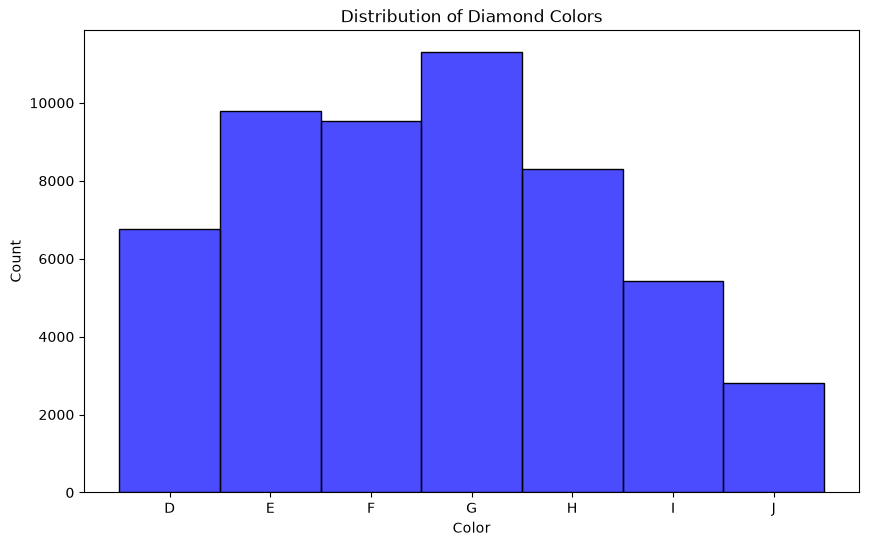

['D', 'E', 'F', 'G', 'H', 'I', 'J']


In [13]:
#histogram for "color" column
#I am using the seaborn library and so I will use the histplot() function to create a histogram for the "color" column.
#Key parameters include:

    #data: The data set, which is often a Pandas DataFrame.
    #x: The variable for which the histogram is plotted.
    #color: To specify the color of the bars.
    #alpha: Transparency of the bars.
    #bins: The number of bins (bar groups) to be used.
    #binwidth: The width of each bin.
    #kde: A boolean to add a Kernel Density Estimate plot.
    #hue: To differentiate data subsets based on another variable.
#https://www.datacamp.com/tutorial/how-to-make-a-seaborn-histogram
#https://www.geeksforgeeks.org/data-visualization/plotting-histogram-in-python-using-matplotlib/


    
plt.figure(figsize=(10, 6))  # Set the figure size
sns.histplot(data=df, x='color', color='blue', alpha=0.7, bins=7)  # Create a histogram for the "color" column
plt.title('Distribution of Diamond Colors')  # Set the title of the plot
plt.xlabel('Color')  # Set the x-axis label
plt.ylabel('Count')  # Set the y-axis label
plt.show()  # Display the plot

print(color_labels)


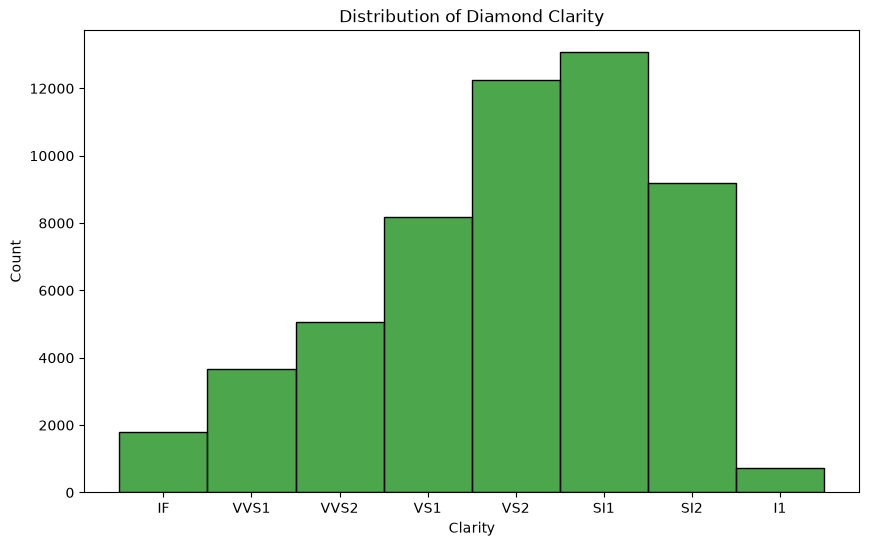

['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']


In [14]:
#Historgram for "clarity" column
plt.figure(figsize=(10, 6))  # Set the figure size
sns.histplot(data=df, x='clarity', color='green', alpha=0.7, bins=8)  # Create a histogram for the "clarity" column
plt.title('Distribution of Diamond Clarity')  # Set the title of the plot   
plt.xlabel('Clarity')  # Set the x-axis label
plt.ylabel('Count')  # Set the y-axis label
plt.show()  # Display the plot

print(clarity_labels)


Findings: For the cut histogram has 5 columns from best to worst and the bars go from the highest to lowest in height. 
For the color and clarity histogram it seems there is skewed because the graphs look like a bell that is not symmetrical since it has a slighlty longer tail on one side. In both the l1 for clarity and J for color column are the lowest meaning the least common or favored, while the the middle categories are the most common. 

# -NUMERICAL FEATURES-

In [15]:
#Numerical input features are those that are not the 3 categorical features we just discussed earlier. 
#Those features would be: 'carat', 'depth', 'table', 'price', 'x', 'y', and 'z'. Price is seperate from the other numerical
#features because it is the target variable we are trying to predict. 

numerical_features = ['carat', 'depth', 'table', 'x', 'y', 'z']


In [16]:
#Calculate and show the descriptive statistics for the numerical variables
df[numerical_features].describe()

#remember: describe() method is built into pandas. It will help me compute a summary statistics for the numerical features, 
#like: count, mean, standard deviation, minimum, 25th percentile (Q1), median (50th percentile or Q2), 75th percentile (Q3), and maximum values for each of the numerical features.
#Count: how many non-null (non-missing) values exists
#Mean: the average value of the feature
#Standard Deviation(std): how spread out the values are from the mean. 
#Minimum: the smallest value of the feature
#25th Percentile (Q1): the value below which 25% of the data falls
#Median (50th Percentile or Q2): the middle value of the feature
#75th Percentile (Q3): the value below which 75% of the data falls
#Maximum: the largest value of the feature


,carat,depth,table,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,10.740000,58.900000,31.800000


In [17]:
#Based on the lecture notes, 
df.describe().T
#this gives us a transposed version of the descriptive statistics, where the rows and columns are switched.
#which is helpful bc now rows are the features and the columns are the statistics
#each feature has its own row bc the .T flip things around
#main advantage is how easy it is to read

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


x, y, z all have a min of 0.0 but in real life length, width and depth can't possibly be 0 mm. It would mean it doesn't exist,but if you take a look at max and carat, so it is existing. Could it be that the measurement starts at 0.0 like the beginning of a ruler, which is why is the minium measurement from where we started. 

In [18]:
#0's in the "x", "y", and "z" columns
#I will check for 0's in the "x", "y", and "z" columns, which represent the dimensions of the diamonds.
#I will use the following code to check for 0's in the "x"
zero_x = (df['x'] == 0).sum()
print(zero_x)
  

8


In [19]:
#I will check for 0's in the "y" column, which represents the width of the diamonds.
zero_y = (df['y'] == 0).sum()
print(zero_y)

7


In [20]:
#I will check for 0's in the "z" column, which represents the depth of the diamonds.
zero_z = (df['z'] == 0).sum() 
print(zero_z)

20


# Show the x,y, z column where there's an instance where any one of the 3 features are 0. Using math that means "OR" (x or y or z) = 0.

In [21]:
df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


# Take each numerical feature and constrcut a histogram and box plot by using class notes example. 

In [22]:
#Notes say:
#for col in df.select_dtypes(include= 'number').columns:
    #select only the numeric columns in the dataframe using select_dtypes() method and loop through each of those columns
    #fig, (ax_box, ax_hist) = plt.subplots(nrows= 2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)})
        #fig is short for figure which will produce 2: box= boxplot and hist= histogram  
    #sns.boxplot(data= df, x= col, ax= ax_box, orient= 'h')
    #sns.histplot(data= df, x= col, ax= ax_hist, bins= 25)
    #ax_box.set(yticks=[])
    #fig.suptitle(f'Skewness: {np.round(df[col].skew(), 4)}')
        #skewness helps measure the asymmetry of the shape and in this case its rounded to 4 decimal places
    #sns.despine(ax=ax_hist)
    #sns.despine(ax=ax_box, left=True)
    #plt.tight_layout()
    
    #https://python-graph-gallery.com/24-histogram-with-a-boxplot-on-top-seaborn/
    

In [23]:
print(numerical_features)

['carat', 'depth', 'table', 'x', 'y', 'z']


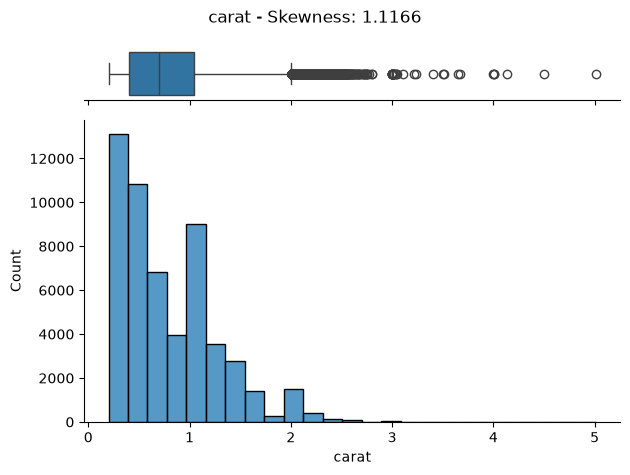

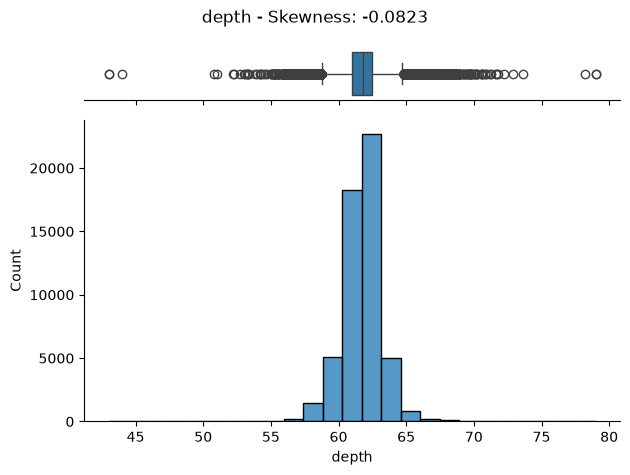

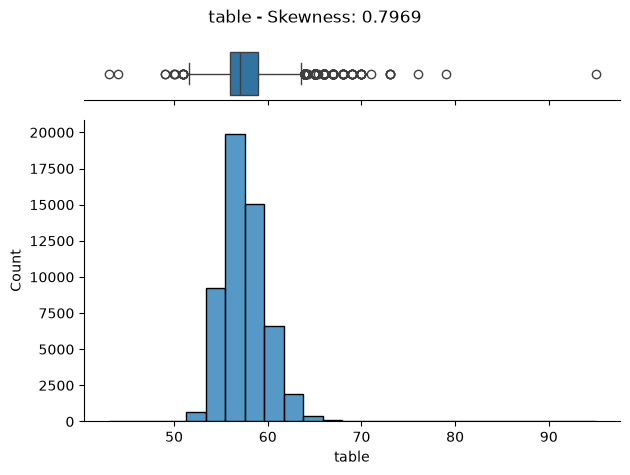

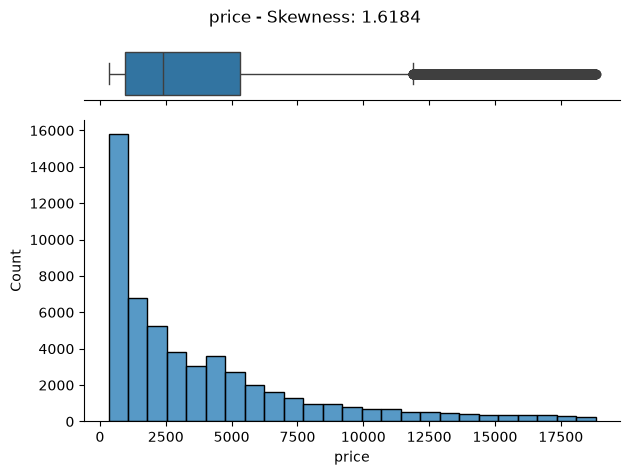

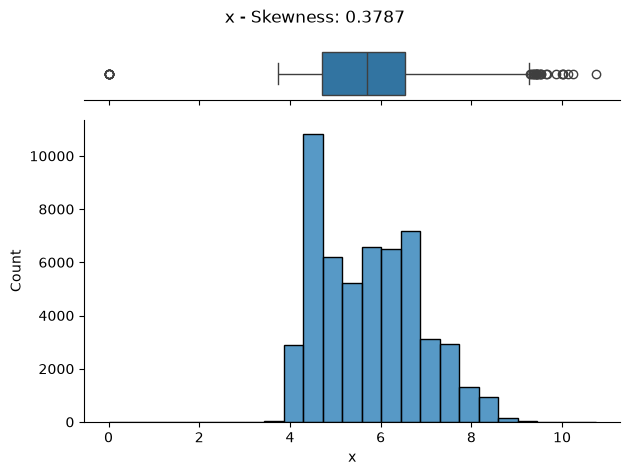

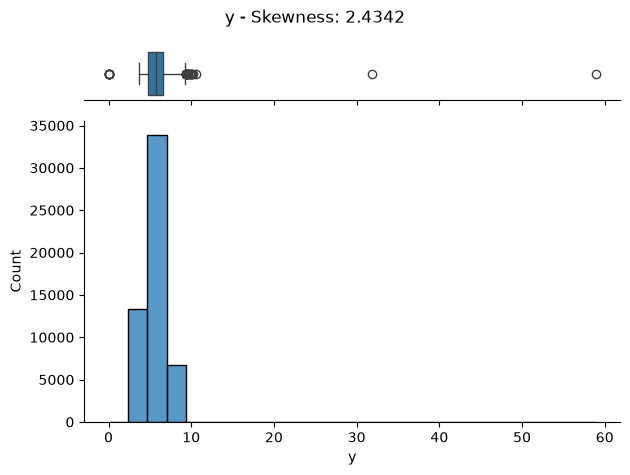

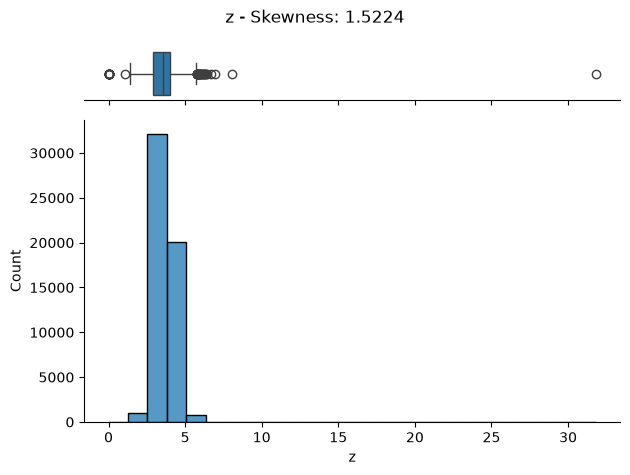

In [24]:
#For the  numerical feature, I will build a boxplot and histogram
#this will produce all  7 numerical features which includes 'price'

for col in df.select_dtypes(include= 'number').columns:
    fig, (ax_box, ax_hist) = plt.subplots(nrows= 2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)})
    sns.boxplot(data= df, x= col, ax= ax_box, orient= 'h')
    sns.histplot(data= df, x= col, ax= ax_hist, bins= 25)
    ax_box.set(yticks=[])
    #want to add a title to each figure to know which numerical feature it is
    fig.suptitle(f'{col} - Skewness: {np.round(df[col].skew(), 4)}')
    sns.despine(ax=ax_hist)
    sns.despine(ax=ax_box, left=True)
    plt.tight_layout()
    

# Show the skewness values for each numerical feature

In [25]:
df[numerical_features].skew()
#looks at the list of numerical features that doesn't include price

carat    1.116646
depth   -0.082294
table    0.796896
x        0.378676
y        2.434167
z        1.522423
dtype: float64

Discussion of skew and distribution for numerical feautures: Table and x have a skew value below 1 which is suppose to be a perfect symmetric distribution, so a nice beatufiul bell shape. However, this are not 0.05 which is closer to 0 so 0.79 and 0.37 have skew without perfect symmetry.  In the previous calculations found out that x,y, and z had zero values which don't help me graphing it and could affect the skew value.

Numerically all the values match,but the figures themselve seem to tell a different story unless I don't know how to see the bell shapes and tails, which has been more than 2 years since I took a statistics course. I know a negative skew value vs a postivie skew value tells me in which direction the tail will be at. 

# Calculate the correlation btwn the numerical features and the target variable, price.

In [26]:
#price = target variable not include in the numerical feature list
#correlation means how these 2 things are related to each other.
#Correlation helps identify if the 2 variables have a positive, negative, or zero relationship with each other.
#https://www.geeksforgeeks.org/data-analysis/exploring-correlation-in-python/

df[numerical_features].corr()
df[numerical_features + ['price']].corr() 
    #this one had the price to price correlation which is 1.000000,and in the notes it is omitted by writing .drop('price') 
df[numerical_features + ['price']].corr()['price']



carat    0.921591
depth   -0.010647
table    0.127134
x        0.884435
y        0.865421
z        0.861249
price    1.000000
Name: price, dtype: float64

Discussion of correlation between numerical features and price: Carat means weight and as it is known the bigger the diamond for an engagement ring the more it cost and it represent social and financial status. So yes, I assume that it matches what we hear on tableoids/TV that the bigger the diamond the pricier it was and the talk of the day or week. 


Depth's value of -0.01 surprised me bc I am unsure why its a negative value if depth helps the shape and form of the diamond. However, if it matters when it comes to pricing a diamond, the value of -0.01 would say no, that depth, its 3D body doesn't impact the price. The form could look the same but it could be small, smaller, big or bigger and that would not affect the price bc the other features would impact the price,but not the depth if its the same in small, smallest and so on. 

# Calculate and show the correlation between the numerical features. Transform the symmetric matrix to a useful DataFrame.

In [27]:
#Notes say: ## Convert the n by n matrix to pairwise table
#corr_df = df.drop(columns= ['mpg']).corr(numeric_only= True).stack().reset_index().rename(columns= {'level_0':'variable1', 'level_1':'variable2', 0:'correlation'})
## Remove the self correlations and symmetry elements
#corr_df = corr_df[corr_df.variable2 > corr_df.variable1]
## Sort by the absolute value
#corr_df = corr_df.loc[corr_df.correlation.abs().sort_values(ascending= False).index]
#corr_df

In [28]:
#correlation maxtrix is a table that seems to take 1 feature and compare it (vs.) another feature
#should not include duplicate comparisons (like price vs. price) and should not include both price vs. carat and carat vs. price since they are the same thing just flipped around

#convert the n by n matrix to pairwise table
corr_df = df[numerical_features + ['price']].corr(numeric_only= True).stack().reset_index().rename(columns= {'level_0':'variable1', 'level_1':'variable2', 0:'correlation'})
#remove duplicate comparisons and self correlations
    #not the 1.0 perfect correlation and not the duplicate comparisons that are the same backward and foward
corr_df = corr_df[corr_df.variable2 > corr_df.variable1]
#sort by the absolute value
corr_df = corr_df.loc[corr_df.correlation.abs().sort_values(ascending= False).index]
corr_df

#abs(). helps convert the negatives to positives and then we can see which ones are the strongest correlations without caring if its positive or negative.

,variable1,variable2,correlation
3,carat,x,0.975094
25,x,y,0.974701
26,x,z,0.970772
5,carat,z,0.953387
33,y,z,0.952006
4,carat,y,0.951722
6,carat,price,0.921591
45,price,x,0.884435
46,price,y,0.865421
47,price,z,0.861249


# Find the numerical features with an absolute correlation value > 0.8

In [29]:
#class notes say:
#corr_df[corr_df.correlation.abs() > 0.7]

corr_df[corr_df.correlation.abs() > 0.8]

,variable1,variable2,correlation
3,carat,x,0.975094
25,x,y,0.974701
26,x,z,0.970772
5,carat,z,0.953387
33,y,z,0.952006
4,carat,y,0.951722
6,carat,price,0.921591
45,price,x,0.884435
46,price,y,0.865421
47,price,z,0.861249


Discussion: rom all this we proof that just like in real life carat affects the price of a diamond and the data confirmed this.
I noticed that x, y , and z have to do with size,but carat also does so they are the "same thing", could say 'redundant'. The correlation between the four variables: carat, x,y, z was pretty high and their information doesn't help me much bc they are the same using different names or variables. Having carat which is a known word would be easier to work with than adding three abstract variables. Removing x,y and z  would be best because I do not believe there is a way to combine carat with the three abstract variables, carat give me a size while x, y and z are more specific sizing/dimensions. Regarding a machine learning it might not be helpful for teaching having all four. Though maybe, the machine learning program could learn that specific sizing matters in sales, making jewelry, or something that I don't know but not sure where x,y and z truly matter. 

# -DATA PREPARATION- PART2

## What and how many zero values are present in x,y,and z numerical features? 

## Look at Part 1(e)(v) where we did the x or y or z = 0 but we want to know each row has more than 1 zero (0) because we will remove those rows. 

In [30]:
#how many zero's per row, sum them up? 
zero_count_per_row = (df[['x', 'y', 'z']] == 0).sum(axis=1)


In [31]:
#to see the records above
df[zero_count_per_row > 1]

,carat,cut,color,clarity,depth,table,price,x,y,z
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.0,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.0,0.00,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.0,0.00,0.0
24520,1.56,Ideal,G,VS2,62.2,54.0,12800,0.0,0.00,0.0
26243,1.20,Premium,D,VVS1,62.1,59.0,15686,0.0,0.00,0.0
27429,2.25,Premium,H,SI2,62.8,59.0,18034,0.0,0.00,0.0
49556,0.71,Good,F,SI2,64.1,60.0,2130,0.0,0.00,0.0
49557,0.71,Good,F,SI2,64.1,60.0,2130,0.0,0.00,0.0


In [32]:
#Keep the row where zero_count_per_row is <= 1 and if > 1 remove them 
df = df[zero_count_per_row <= 1]
#to see the updated data with 8 records removed; the data started with 53940 records and now has 53932 records after removing the 8 records with more than 1 zero in the x,y, and z columns.
df.shape


(53932, 10)

In [33]:
df[df['z'] == 0] #to see only the records with a 0 in the z column, which is the depth of the diamond.
#these are the rows left after the removal of the 8 records with more than 1 zero in the x,y, and z columns.

,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0
26123,2.25,Premium,I,SI1,61.3,58.0,15397,8.52,8.42,0.0
27112,2.20,Premium,H,SI1,61.2,59.0,17265,8.42,8.37,0.0
27503,2.02,Premium,H,VS2,62.7,53.0,18207,8.02,7.95,0.0


## Now the only rows that have zero are in the z column (depth), 12 records. 
Depth = z / (avg of x and y) 

For the expression we want z alone, z = depth * (avg of x and y)

Depth is a % so it needs to converted to a decimal
z = (depth / 100) * (avgof x and y)
# Find an expression for z and impute the zero values

In [34]:
#Using pandas or Numpy, we will rewrite the formula using "where"
#formula z = (depth/100) * (avg of x and y)
depth_conversion = df['depth'] / 100
avg_xy = (df['x'] + df['y']) / 2
calculated_z = depth_conversion * avg_xy
#Apply the formula only to the rows where z is 0.
df['calculated_z'] = np.where(df['z'] == 0, calculated_z, df['z'])

In [35]:
#Now to look at those 12 rows where z was 0 and next to it should be the new calculated_z value that was calculated using the formula 
df[df['z'] == 0][['depth', 'x', 'y', 'z', 'calculated_z']]

,depth,x,y,z,calculated_z
2207,59.1,6.55,6.48,0.0,3.850365
2314,58.1,6.66,6.60,0.0,3.852030
4791,63.0,6.50,6.47,0.0,4.085550
5471,59.2,6.50,6.47,0.0,3.839120
10167,64.0,7.15,7.04,0.0,4.540800
13601,59.2,6.88,6.83,0.0,4.058160
24394,59.4,8.49,8.45,0.0,5.031180
26123,61.3,8.52,8.42,0.0,5.192110
27112,61.2,8.42,8.37,0.0,5.137740
27503,62.7,8.02,7.95,0.0,5.006595


In [36]:
#Now I can replace the original z column with the new calculated_z column, and then drop the calculated_z column since it is no longer needed.
df['z'] = df['calculated_z']
df = df.drop(columns=['calculated_z'])

In [37]:
#check to see if there are any more 0's in the z column
#nothing should show up bc no row should have a 0 in the z column now since I replaced the 0's with the calculated_z values
df[df['z'] == 0]

,carat,cut,color,clarity,depth,table,price,x,y,z


In [38]:
(df['z'] == 0).sum()
#this is done to confirm that there are no more 0's in the z column and the output should be 0

np.int64(0)

# Show the updated descriptive statistics for the numerical features 

In [39]:
df[numerical_features].describe()

,carat,depth,table,x,y,z
count,53932.000000,53932.000000,53932.000000,53932.000000,53932.000000,53932.000000
mean,0.797879,61.749336,57.457029,5.732007,5.735254,3.540265
std,0.473986,1.432514,2.234064,1.119670,1.140343,0.702667
min,0.200000,43.000000,43.000000,3.730000,3.680000,1.070000
25%,0.400000,61.000000,56.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,10.740000,58.900000,31.800000


In [40]:
#rows now after removal of 8 
df.shape[0]


53932

## x, y, and z should be bound on 1mm minimum and 11mm maximum,  
## 1mm <= x,y,z <= 11mm. 
## Show where the data is outside these bounds

In [41]:
#Outside the bounds for x column, meaning x < 1 OR x > 11
df[(df['x'] < 1) | (df['x'] > 11)]

,carat,cut,color,clarity,depth,table,price,x,y,z


In [42]:
#Outside the bounds for y column, meaning y < 1 OR y > 11
df[(df['y'] < 1) | (df['y'] > 11)]

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.9,8.06
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.8,5.12


In [43]:
#Outside the bounds for z column, meaning z < 1 OR z > 11
df[(df['z'] < 1) | (df['z'] > 11)]

,carat,cut,color,clarity,depth,table,price,x,y,z
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.8


In [44]:
#I must remove these 3 rows from above since they are outside the bounds of the x, y, and z columns. 
#the condition could be reversed to be used to keep the rows that are within the bounds of the x, y, and z columns.

df = df[(df['x'] >= 1) & (df['x'] <= 11) & (df['y'] >= 1) & (df['y'] <= 11) & (df['z'] >= 1) & (df['z'] <= 11)]

In [45]:
#To see that the rows were removed, we last had 53932 rows and now we have 53929 rows after removing the 3 rows that were outside the bounds of the x, y, and z columns.
df.shape[0]

53929

# Calculate and show the number of duplicated rows

In [46]:
df.duplicated()
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html
#Bc I imported  the pandas library the code command for checking for duplicates is df.duplicated() and it will return a boolean series indicating whether each row is a duplicate of a previous row.

0        False
1        False
2        False
3        False
4        False
         ...  
53935    False
53936    False
53937    False
53938    False
53939    False
Length: 53929, dtype: bool

In [47]:
df.duplicated().sum()

np.int64(145)

In [48]:
#To see the actual duplicate rows, we can use the following code:
#It says 145 just like the code above told me,but I can see the actual rows that are duplicates and it shows the first 5 rows and last 5 rows
df[df.duplicated()]

,carat,cut,color,clarity,depth,table,price,x,y,z
1005,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
2025,1.52,Good,E,I1,57.3,58.0,3105,7.53,7.42,4.28
...,...,...,...,...,...,...,...,...,...,...
47296,0.30,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
47969,0.52,Ideal,D,VS2,61.8,55.0,1919,5.19,5.16,3.20
49326,0.51,Ideal,F,VVS2,61.2,56.0,2093,5.17,5.19,3.17
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203,5.19,5.17,3.17


# Remove the duplicated rows from the data set

In [49]:
df = df.drop_duplicates()
#the command drop_duplicates() will remove the duplicate rows from the dataframe and keep only the first occurrence of each duplicate row.

In [50]:
#To verify they have been removed (dropped), we can check the dataset again to see its total number of rows and columns
#53929 - 145 = 53784
df.shape

(53784, 10)

# -SKEW AND CORRELATIONS-

## Calculate the skew for the numerical features

In [51]:
df[numerical_features].skew()
#the results for x, y, and z look different from the first time  I ran the .skew() command
#these three are now close and around the same value: 0.39
#this could of been influenced by removing rows that were duplicates/typos or those with a lot of 0's in the x, y, and z columns or those outside the bounds of the x, y, and z columns.
#this is new to me and it is interesting to see what skew is 

carat    1.113733
depth   -0.113829
table    0.791614
x        0.396972
y        0.391432
z        0.391866
dtype: float64

## Recalculate and show the correlation btwn the numerical features and target variable, 'price'

In [52]:
#price is not part of the numerical features list, REMEMBER?!!
#also will use .corr() to see the correlation between price and the other numerical features
df[numerical_features + ['price']].corr()['price']

#again the values for x, y, and z are different from the first time I ran the .corr() command and they are now all around the same value: 0.88

carat    0.921561
depth   -0.011008
table    0.126582
x        0.887122
y        0.888713
z        0.882001
price    1.000000
Name: price, dtype: float64

## Recalculate and show the correlation btwn ONLY the numerical features

In [53]:
#Feature vs Feature within numerical features, not including price.
df[numerical_features].corr()

,carat,depth,table,x,y,z
carat,1.000000,0.027948,0.181126,0.977842,0.976924,0.976518
depth,0.027948,1.000000,-0.297570,-0.025227,-0.028343,0.096322
table,0.181126,-0.297570,1.000000,0.195483,0.189301,0.155145
x,0.977842,-0.025227,0.195483,1.000000,0.998654,0.991090
y,0.976924,-0.028343,0.189301,0.998654,1.000000,0.990746
z,0.976518,0.096322,0.155145,0.991090,0.990746,1.000000


In [54]:
#The version from class notes
#correlation maxtrix is a table that seems to take 1 feature and compare it (vs.) another feature
#should not include duplicate comparisons (like price vs. price) and should not include both price vs. carat and carat vs. price since they are the same thing just flipped around

#convert the n by n matrix to pairwise table
corr_df = df[numerical_features + ['price']].corr(numeric_only= True).stack().reset_index().rename(columns= {'level_0':'variable1', 'level_1':'variable2', 0:'correlation'})
#remove duplicate comparisons and self correlations
    #not the 1.0 perfect correlation and not the duplicate comparisons that are the same backward and foward
corr_df = corr_df[corr_df.variable2 > corr_df.variable1]
#sort by the absolute value
corr_df = corr_df.loc[corr_df.correlation.abs().sort_values(ascending= False).index]
corr_df

#abs(). helps convert the negatives to positives and then we can see which ones are the strongest correlations without caring if its positive or negative.

,variable1,variable2,correlation
25,x,y,0.998654
26,x,z,0.991090
33,y,z,0.990746
3,carat,x,0.977842
4,carat,y,0.976924
5,carat,z,0.976518
6,carat,price,0.921561
46,price,y,0.888713
45,price,x,0.887122
47,price,z,0.882001


Discussion: From Part 1 to now I can see how the numbers have changed, are closer to each other and the skew for x,y,and z changed and the correlation between carat,x,y,z and price seemed to have gotten stronger and closer in value to each other. 
I have learned that for the future I must use my amazing skill of attention to detail to see what the results show and question them or be curious as to why they are high or really low or not similar and closer to each other. Duplicates, missing values, zeros, mistyped entries all make a difference even if my data is thousands of rows long. 
In real life it reminded me of voting and how miscounted votes can affect the election results, even though you would think they don't matter or would make much of a difference,but these results from this data set have shown me that they do. 
Cleaning the data helped me see the relationships, correlations, and connections they have with each other and to see what I am seeking to find out much more better. In my personal life I love cleaning and I want to learn more about cleaning data and know the procedures and commands. I believe I will enjoy cleaning at data and learning how to prepare it to be used for the presentation step. 

# -DATA PARTITIONING-

### Split the data into Training and Testing data sets. Once you done that, set aside 20% for the Testing data and set the "random_state" for reproducibility.

Data gets split into 2 parts: 

Training set (80%) - used to teach the model

Testing set (20%) - kept hidden during training, used to check how well the model performs/does with data it hasn't seen

In [55]:
#Notes say:
#from sklearn.model_selection import train_test_split

##X_train, X_test, y_train, y_test = train_test_split(df.drop(columns= 'mpg'), 
                        #df.drop(columns= 'mpg') is the target variable 'mpg' from the dataframe. This means that all other columns in the dataframe will be used as features for training and testing the model.
                        #in our dataset, the target variable is 'price'
                ##df['mpg'],  #target variable column
                ##test_size= 0.25, #splits the data 75% for training and 25% for testing
                ##random_state= 432)

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns='price'), #df.drop(columns= 'price') means it won't include the 'price' column. 
    df['price'], #target variable column
    test_size=0.20, #splits the data 80% for training and 20% for testing
    random_state=432
)

In [57]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape
#X_train.shape = means my training data has 43027 rows and 9 columns,
#X_test.shape = means my testing data has 10757 rows and 9 columns, 
# y_train.shape = means my training target variable has 43027 rows and 1 column, 
# y_test.shape = means my testing target variable has 10757 rows and 1 column (price values for testing data)

#(53784, 10) was my total before I splitted the data: 43027 + 10,757 = 53,784 rows and 9 + 1 = 10 columns
#THIS WAS TO VERIFY THAT THE SPLIT WAS DONE CORRECTLY AND THAT THE TOTAL NUMBER OF ROWS AND COLUMNS MATCHES UP WITH THE ORIGINAL LAST DATAFRAME

((43027, 9), (10757, 9), (43027,), (10757,))

## Create an instance of Linear Regression. Train the instance with only the carat feature from the Training Data.

In [58]:
#Carat is the most important feature in predicting the price of a diamond. 
# It has the highest correlation with price among all the features. 
# Carat column will be used for training and testing the model
X_train_carat = X_train[['carat']]
X_test_carat = X_test[['carat']]

#a model for the carat column
carat_model = LinearRegression()

#Train the model using the training data
carat_model.fit(X_train_carat, y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7777.55]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['carat']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2270
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


# -SIMPLE MODEL-PART 3

## Using the Training Data created from Part2(e), draw a scatter plot of price vs. carat

Carat at max price: carat    2.29
Name: 27749, dtype: float64


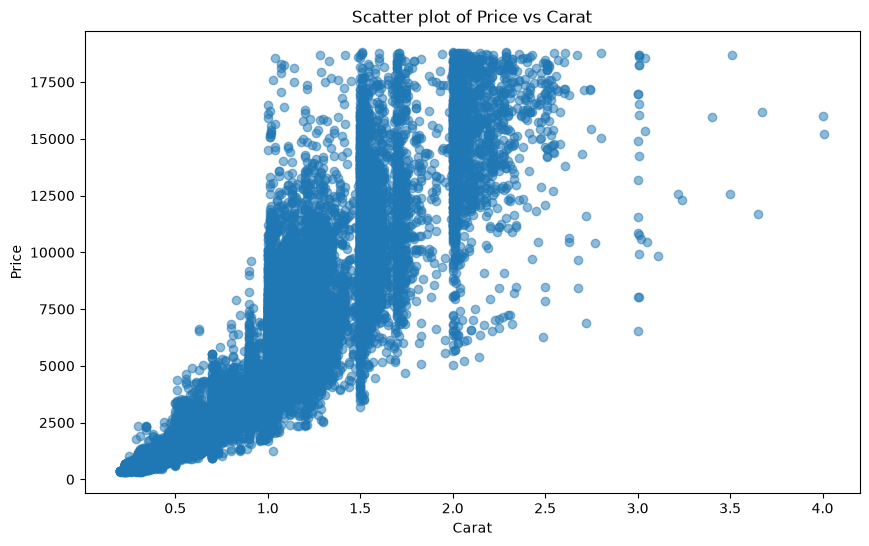

In [59]:
#Scatter plot price vs carat
plt.figure(figsize=(10, 6)) #size of the plot
plt.scatter(X_train_carat, y_train, alpha=0.5) #scatter plot of carat vs price
        #alpha=0.5 makes the points semi-transparent; help visualize overlapping points in the scatter plot.
plt.xlabel('Carat')
plt.ylabel('Price')
plt.title('Scatter plot of Price vs Carat')
#to see the max value for price in this scatter plot
max_price = y_train.idxmax()
carat_at_max_price = X_train_carat.loc[max_price]
print(f'Carat at max price: {carat_at_max_price}')
plt.show()
#points are overlapping each other and the scatter plot is not very clear
#I have learned that overplotting can occur when there are many data points in a scatter plot

Findings Discussion: Vertical lines seem to be drawn or noticeable at Carat 1.5, 2.0, and 3.0 which are whole numbers meanign a complete size. 
The carat size between 2.5 to 3.0 and after don't seem to be popular because there show less dots or its emptier. Even the 3.0 vertical line is very thin. 
The tornado shape below 1.5 carat means there's a lot of diamonds of that size and cheaper. The tornado prices covered are 0-9,000. 
The highest price was the carat at 2.29 which might be the middle/center from 0 to 4.0 across the x-axis.

## Make predictions on data by prediciting the outcome using the Testing Data from Part 2(e). Calculate and present RMSE and MAE.

In [60]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

y_pred = carat_model.predict(X_test_carat)
rmse_testingdata = root_mean_squared_error(y_test, y_pred)
mae_testingdata = mean_absolute_error(y_test, y_pred)
print(f'RMSE on testing data: {rmse_testingdata}')
print(f'MAE on testing data: {mae_testingdata}')


RMSE on testing data: 1537.7988728879602
MAE on testing data: 1002.9311087114684


## From the trained Linear Regression instance, show the slope and intercept coefficients.

In [61]:
#Follows the formula y = mx + b, where m is the slope and b is the y-intercept.
# y = price, m = coefficient (slope) for carat, x = carat, b = intercept (y-intercept)
#single linear regression involves 1 independent variable (feature) and 1 dependent variable (target). 
# In this case, the independent variable is 'carat' and the dependent variable is 'price'. 
#Multi linear regression involves 2 or more independent variables (features) and 1 dependent variable (target).

print(f'Coefficient (slope) for carat: {carat_model.coef_[0]}')
print(f'Intercept (y-intercept): {carat_model.intercept_}')


Coefficient (slope) for carat: 7777.548105000178
Intercept (y-intercept): -2269.6371641541878


## Create a scatter plot with the following: price vs carat from Testing Data, predictions found from Testing Data in 3(d) vs carat

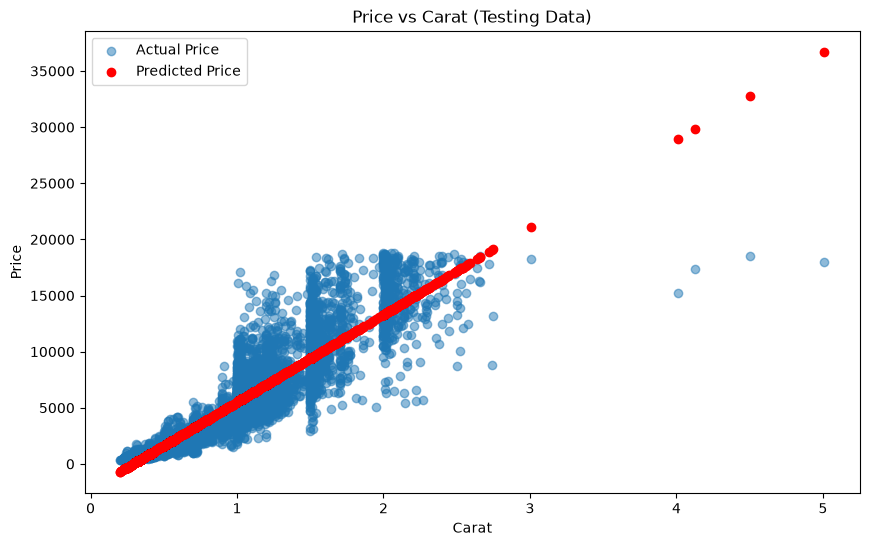

In [62]:
#Scatter plot with price vs carat from Testing Data + predictions
plt.figure(figsize=(10, 6)) #size of the plot
plt.scatter(X_test_carat, y_test, alpha=0.5) #scatter plot of carat vs price

plt.xlabel('Carat')
plt.ylabel('Price')
plt.title('Price vs Carat (Testing Data)')
#predictions
y_pred_carat = carat_model.predict(X_test_carat)
plt.scatter(X_test_carat, y_pred_carat, color='red', linewidth=1)
#adding a legend 
plt.legend(['Actual Price', 'Predicted Price'], loc='upper left')
plt.show()

Findings Discussion: At the 3.0, 3.5 and 4.0 mark there are red dots but hardly any blue dots data to compare it to. (Rare to find diamonds of these carat sizes) They stand alone, why is that?  I assume this can't be good for predictions if there is nothing to say bc of this when there's blue dots below but quite some distance from the red ones. 
From the tornado section the red line seems to almost sit at a halfway point/middle before the 1.5 and maybe at 1.5. From 2.0 carat size there is no balance between the actual prices and the predicted prices as the predicted price line slopes is going up positively. 

# -MODELS WITH MORE INPUT FEATURES- PART 4

### Ordinal Encoding of Categorical Features
### Employ Ordinal Encoder, StandardScaler, ColumnTransformer to construct a ColumnTransformer instance 
### Construct transformed Training and Testing data sets 

In [63]:
#Notes say:
##oh_encoder = OneHotEncoder(sparse_output= False)

##column_transformer = \
##ColumnTransformer(transformers= [('ohe_enc', oh_encoder, ['origin'])],
##                  remainder= 'passthrough',
##                  #the remainder here is to leave out the columns that are not specified in the transformers list 
##                  verbose_feature_names_out= False
##                 )

##column_transformer.fit(X= X_train) #this here will take X_train and fit the column_transformer to it

##X_train_encoded_origin = \
##pd.DataFrame(data= column_transformer.transform(X= X_train), 
##             columns= column_transformer.get_feature_names_out(),
##             index= X_train.index)

##X_test_encoded_origin = \
##pd.DataFrame(data= column_transformer.transform(X= X_test), 
##             columns= column_transformer.get_feature_names_out(),
##             index= X_test.index)

In [64]:
#Create OrdinalEncoder for the categorical features
ordinal_encoder = OrdinalEncoder(categories=[cut_labels, color_labels, clarity_labels])

#Creating the StandardScaler for the numerical features
standard_scaler = StandardScaler()

In [65]:
#Create a ColumnTransformer for all columns both numerical and categorical
column_transformer = ColumnTransformer(
    transformers=[
        ('ordinal', ordinal_encoder, categorical_features),
        ('scale', standard_scaler, numerical_features)
    ]
)

### In machine learning models that use Linear Regression ONLY understand numbers and my categorical features are text/words and so the model can't work with that. 

### Ordinal Encoder will help me convert the categorical features text into a ran order so they have a numerical order/relationship. EX: Fair = 0, Good = 1, ...etc like on = 1 / off = 0 , hot = 1 /cold = 0

### Standard Scaler will take the numerical features columns and give them the same scale since their scales didn't match.

### Column Tranformer will let me select many different columns and apply "transformations"

In [66]:
#Now to use the top on the training and testing data,
X_train_ordered_scaled = column_transformer.fit_transform(X_train)
#verify to see the shape of the transformed training data
X_train_ordered_scaled.shape
    #price column is not included in the transformed training data since it is the target variable 


(43027, 9)

In [67]:
print(X_train_ordered_scaled)

[[ 2.          1.          3.         ... -0.92427892 -0.91460218
  -0.84100231]
 [ 0.          5.          4.         ...  2.49013814  2.44316942
   2.48947953]
 [ 4.          3.          6.         ...  2.31137285  2.17310736
   2.54740095]
 ...
 [ 3.          3.          2.         ... -0.62037792 -0.59052771
  -0.46451306]
 [ 1.          2.          4.         ...  0.05893018 -0.01439532
  -0.23282737]
 [ 0.          5.          6.         ...  1.42648466  1.47994807
   1.47585462]]


In [68]:
#Transforming the testing data using the same column_transformer
#here we are using .transform() instead of .fit_transform() because we want to use the same transformation that was fitted on the training data to transform the testing data.
X_test_ordered_scaled = column_transformer.transform(X_test)

#Verify to see the shape of the transformed testing data
X_test_ordered_scaled.shape

(10757, 9)

In [69]:
print(X_test_ordered_scaled)
#to see them more clearly and organized

X_test_ordered_scaled_df = pd.DataFrame(X_test_ordered_scaled, columns= categorical_features + numerical_features)
print(X_test_ordered_scaled_df)

[[ 0.          2.          5.         ... -0.88852586 -0.93260632
  -0.84100231]
 [ 2.          6.          5.         ...  1.1136454   1.1558736
   1.1862475 ]
 [ 0.          4.          4.         ... -0.67400751 -0.65354219
  -0.6817184 ]
 ...
 [ 1.          3.          4.         ...  1.01532449  0.95782809
   1.01248323]
 [ 1.          0.          5.         ... -0.05726726 -0.12242014
  -0.01562203]
 [ 2.          2.          6.         ...  0.86337399  0.93082189
   0.94008145]]
       cut  color  clarity     carat     depth     table         x         y  \
0      0.0    2.0      5.0 -0.822041  0.665593 -0.203861 -0.888526 -0.932606   
1      2.0    6.0      5.0  1.083034  0.386315 -1.097967  1.113645  1.155874   
2      0.0    4.0      4.0 -0.716203 -0.172240 -1.097967 -0.674008 -0.653542   
3      0.0    1.0      5.0  0.215166  0.107037 -1.545020  0.407523  0.435708   
4      0.0    4.0      2.0 -1.033716  0.595774 -0.650914 -1.219242 -1.274685   
...    ...    ...      ...   

In [70]:
X_test_ordered_scaled_df.dtypes
#helps me see the data types of each column in the transformed testing data
#I want to see that the categorical features are now numerical and the numerical features are now scaled (standardized)

cut        float64
color      float64
clarity    float64
carat      float64
depth      float64
table      float64
x          float64
y          float64
z          float64
dtype: object

In [71]:
X_test_ordered_scaled_df.describe()

,cut,color,clarity,carat,depth,table,x,y,z
count,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000
mean,1.096774,2.579065,3.953983,-0.006820,0.004927,0.004683,-0.009524,-0.009798,-0.009004
std,1.120412,1.681556,1.653406,1.009675,0.991392,0.991895,1.000198,0.999399,1.004446
min,0.000000,0.000000,0.000000,-1.266558,-5.967256,-3.288526,-1.791291,-1.850817,-3.085457
25%,0.000000,1.000000,3.000000,-0.843208,-0.521338,-0.650914,-0.915341,-0.914602,-0.913404
50%,1.000000,3.000000,4.000000,-0.208184,0.037218,-0.203861,-0.039391,-0.032399,-0.044583
75%,2.000000,4.000000,5.000000,0.511511,0.525954,0.690244,0.711423,0.714772,0.708396
max,4.000000,6.000000,7.000000,8.915006,6.879526,6.948984,4.474433,4.324602,4.980101


In [72]:
#for my training data, I will create a DataFrame from the transformed training data and then check the data types and descriptive statistics of each column in the transformed training data.
X_train_ordered_scaled_df = pd.DataFrame(X_train_ordered_scaled, columns= categorical_features + numerical_features)

#X_train_ordered_scaled_df.describe()
X_train_ordered_scaled_df.describe().T #flips so each feature has its own row and the columns are the statistics

#Controlling the decimal places for the descriptive statistics of the transformed training data
X_train_ordered_scaled_df.describe().T.round(4) #rounds to 4 decimal places


,count,mean,std,min,25%,50%,75%,max
cut,43027.0,1.0956,1.1150,0.0000,0.0000,1.0000,2.0000,4.0000
color,43027.0,2.5977,1.7060,0.0000,1.0000,3.0000,4.0000,6.0000
clarity,43027.0,3.9465,1.6452,0.0000,3.0000,4.0000,5.0000,7.0000
carat,43027.0,0.0000,1.0000,-1.2666,-0.8432,-0.2082,0.5115,6.7983
depth,43027.0,-0.0000,1.0000,-13.0888,-0.5213,0.0372,0.5260,12.0462
table,43027.0,0.0000,1.0000,-6.4626,-0.6509,-0.2039,0.6902,16.7841
x,43027.0,0.0000,1.0000,-1.7913,-0.9064,-0.0305,0.7204,3.9381
y,43027.0,0.0000,1.0000,-1.8238,-0.9146,-0.0234,0.7238,3.9285
z,43027.0,0.0000,1.0000,-3.5778,-0.9134,-0.0156,0.7229,4.1113


## Create an instance of Linear Regression and train the instance with the ordinal encoded Training Data

In [73]:
#Linear Regression Instance
X_train_order_scaled_model = LinearRegression()
X_train_order_scaled_model.fit(X_train_ordered_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ -122.37, -324.44, -497.41,...,-2007.36, 2510.27,-1654.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6879
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](9,)","[468.07,355.29,272.96,..., 35.86, 7.98, 7.38]"


### Evaluate this regression model by predicting the outcomes using the ordinal encoded Testing Data from above and use these Testing  Data predictions to caculate RMSE and MAE

In [78]:
# Testing Data from the transformed testing data to make predictions to calculate the RMSE and MAE for the model

# Assuming `model` is your trained model and `X_test_ordered_scaled_model` and `y_test` are your testing data
y_pred_transformed = X_train_order_scaled_model.predict(X_test_ordered_scaled)
rmse_transformed = root_mean_squared_error(y_test, y_pred_transformed)
mae_transformed = mean_absolute_error(y_test, y_pred_transformed)
print(f'RMSE on transformed testing data: {rmse_transformed}')
print(f'MAE on transformed testing data: {mae_transformed}')

RMSE on transformed testing data: 1221.948745611653
MAE on transformed testing data: 799.3743005448358


In [80]:
# To see and compare the RMSE and MAE values for the model trained on the transformed data with the model trained on the carat feature only
#Carat-only model: Trained on X_train_carat and y_train (carat column from training data), tested on X_test_carat and y_test (just carat column from testing data)
print(f'Carat-only model: RMSE: {rmse_testingdata}, MAE: {mae_testingdata}') #ONLY CARAT FEATURE WAS USED HERE
print()
print(f'Ordinal encoded and scaled model: RMSE: {rmse_transformed}, MAE: {mae_transformed}') 
    #Ordinal encoded and scaled model: Trained on X_train_ordered_scaled and y_train (transformed training data), tested on X_test_ordered_scaled and y_test (transformed testing data)
    #USED ALL AVAILABLE FEATURES IN THE DATASET

comparison_df_chart = pd.DataFrame({
    'Model': ['Carat-only', 'Ordinal encoded and scaled'],
    'RMSE': [rmse_testingdata, rmse_transformed],
    'MAE': [mae_testingdata, mae_transformed]
})
comparison_df_chart

Carat-only model: RMSE: 1537.7988728879602, MAE: 1002.9311087114684

Ordinal encoded and scaled model: RMSE: 1221.948745611653, MAE: 799.3743005448358


,Model,RMSE,MAE
0,Carat-only,1537.798873,1002.931109
1,Ordinal encoded and scaled,1221.948746,799.374301


In [82]:
carat_model.n_features_in_
X_train_order_scaled_model.n_features_in_
print(f'Carat-only model: Number of features: {carat_model.n_features_in_}')
print(f'Ordinal encoded and scaled model: Number of features: {X_train_order_scaled_model.n_features_in_}')
#i was not believing and needed reassurance that the carat-only model had 1 feature and the ordinal encoded and scaled model had 9 features
#Very new concepts/check notes! DON'T FORGET TO VERIFY AND CHECK AS YOU GO !

Carat-only model: Number of features: 1
Ordinal encoded and scaled model: Number of features: 9


### Show the weight coefficients from LinearRegression instance trained on the ordinal encoded model.

In [84]:
#Presenting the weight coefficients from the trained model
#Adapted the print formatting style from the lecture notebook (mpg_models2) that compares Normal Equation vs Scikit-Learn coefficients,
#Mostly just shows the weight coefficients for each feature in the model
print(f'{"Feature":<15}{"Coefficient":>15}')
for name, coef in zip(column_transformer.get_feature_names_out(), X_train_order_scaled_model.coef_):
    print(f'{name:<15}{coef:>15.3f}')
print(f'{"Intercept":<15}{X_train_order_scaled_model.intercept_:>15.3f}')

Feature            Coefficient
ordinal__cut          -122.370
ordinal__color        -324.445
ordinal__clarity       -497.407
scale__carat          5273.473
scale__depth            90.647
scale__table           -47.445
scale__x             -2007.361
scale__y              2510.271
scale__z             -1654.866
Intercept             6879.479


Findings Discussion: The categorical features now have a ranking order from best to worst that is numerical. Those numbers change the prediction because the higher number is the worst quality when the lower numbers should have more influence in the predictions and not the worst numerical values and in the chart above the ordinal_cut, ordinal_color, and ordinal_clarity have all negative numbers. The three negative values must mean that each of these features goes up in value, for example 'cut' it would mean quality is getting worse bc the highest number are the worst conditions, 'Fair'. Meaning worse quality diamonds would not or could not sell for high prices and might less expensive compare to those with 'Ideal' conditions in the cut feature.  For color and clarity this must hold true too, the values or rank given are higher on the worse side would lead to a lower/less expensive price. 

# -One Hot Encoding of Categorical Features-

In [94]:
#Ordinal Encoder assumes that the categorical features have a natural order or ranking.
#That for 'cut' Fair < Good < Very Good < Premium < Ideal, 
#for 'color' D < E < F < G < H < I < J, and for 'clarity' I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF.
#So assigns them numerical values based on their order,but not always the best approach
#Instead OneHotEncoder is often preferred for categorical features without a natural order, as it creates binary columns for each category
#Goes back to hot = 0, cold = 1 or I can say hot = 1, cold = 0. It is a binary representation of the categorical variable.
#The teacher said that I could say something and it would have a 1 in the categorical column and a 0 in the other categorical column.
#OneHotEncoder MAKES NO assumptions about the order of the categories 

onehot_encoder = OneHotEncoder(sparse_output=False, drop='first')
column_transformer_onehot = ColumnTransformer(
    transformers=[
        ('onehot', onehot_encoder, categorical_features),
        ('scale', standard_scaler, numerical_features)
    ]
)

#now to fit the column_transformer_onehot to the training data and transform both the training and testing data
X_train_ohe = column_transformer_onehot.fit_transform(X_train)
X_test_ohe = column_transformer_onehot.transform(X_test)

In [95]:
#
pd.DataFrame(X_train_ohe, columns=column_transformer_onehot.get_feature_names_out()).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
onehot__cut_Good,43027.0,0.091,0.288,0.000,0.000,0.000,0.000,1.000
onehot__cut_Ideal,43027.0,0.399,0.490,0.000,0.000,0.000,1.000,1.000
onehot__cut_Premium,43027.0,0.256,0.436,0.000,0.000,0.000,1.000,1.000
onehot__cut_Very Good,43027.0,0.224,0.417,0.000,0.000,0.000,0.000,1.000
onehot__color_E,43027.0,0.181,0.385,0.000,0.000,0.000,0.000,1.000
onehot__color_F,43027.0,0.175,0.380,0.000,0.000,0.000,0.000,1.000
onehot__color_G,43027.0,0.209,0.407,0.000,0.000,0.000,0.000,1.000
onehot__color_H,43027.0,0.154,0.361,0.000,0.000,0.000,0.000,1.000
onehot__color_I,43027.0,0.102,0.302,0.000,0.000,0.000,0.000,1.000
onehot__color_J,43027.0,0.053,0.223,0.000,0.000,0.000,0.000,1.000


### Create an instance of Linear Regression and train the instance with the one hot enconded Training Data

In [96]:
#Linear Regression Instance for OneHotEncoded data
X_train_ohe_model = LinearRegression()
X_train_ohe_model.fit(X_train_ohe, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](23,)","[ 442.84, 696.27, 656.87,...,-1795.66, 1859.44,-1443.94]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-36.14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,23
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(23)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](23,)","[416.92,239.62,181.69,..., 8.86, 7.96, 6.74]"


### Evaluate the regression model by predicting the outcomes using one hot encoded Testing Data. Use the predictions to calculate RMSE and MAE

In [97]:
y_pred_ohe = X_train_ohe_model.predict(X_test_ohe)
rmse_ohe = root_mean_squared_error(y_test, y_pred_ohe)
mae_ohe = mean_absolute_error(y_test, y_pred_ohe)
print(f'RMSE on OneHotEncoded testing data: {rmse_ohe}')
print(f'MAE on OneHotEncoded testing data: {mae_ohe}')

RMSE on OneHotEncoded testing data: 1131.678009182748
MAE on OneHotEncoded testing data: 732.0155365545953


In [101]:
#To see now the OneHotEncoded model, the Ordinal encoded and scaled model, and the Carat-only model all together in a chart for comparison
#Reminder: The Ordinal encoded and scaled model used all available features and from best to worst gave ranking value to all categorical features
#The OneHotEncoded model used all available features and created binary columns for each category in the categorical features, without assuming any order or ranking.
#The carat-only model uses only the carat feature to predict the price of the diamonds. The data it uses is the original training and testing data without any transformations or encoding applied to the categorical features.
comparison_df_chart = pd.DataFrame({
    'Model': ['Carat-only', 'Ordinal encoded and scaled', 'OneHotEncoded'],
    'RMSE': [rmse_testingdata, rmse_transformed, rmse_ohe],
    'MAE': [mae_testingdata, mae_transformed, mae_ohe]
})
comparison_df_chart

,Model,RMSE,MAE
0,Carat-only,1537.798873,1002.931109
1,Ordinal encoded and scaled,1221.948746,799.374301
2,OneHotEncoded,1131.678009,732.015537


### Present the weight coefficients from the LinearRegression instanced trained on the one hot encoded and standardized data. 

In [102]:
print(f'{"Feature":<20}{"Coefficient":>15}')
for name, coef in zip(column_transformer_onehot.get_feature_names_out(), X_train_ohe_model.coef_):
    print(f'{name:<20}{coef:>15.3f}')
print(f'{"Intercept":<20}{X_train_ohe_model.intercept_:>15.3f}')

Feature                 Coefficient
onehot__cut_Good            442.835
onehot__cut_Ideal           696.270
onehot__cut_Premium         656.872
onehot__cut_Very Good        559.745
onehot__color_E            -209.629
onehot__color_F            -279.074
onehot__color_G            -488.830
onehot__color_H            -988.099
onehot__color_I           -1491.265
onehot__color_J           -2358.145
onehot__clarity_IF         5324.576
onehot__clarity_SI1        3651.080
onehot__clarity_SI2        2690.758
onehot__clarity_VS1        4563.475
onehot__clarity_VS2        4252.941
onehot__clarity_VVS1       4973.145
onehot__clarity_VVS2       4939.741
scale__carat               5544.006
scale__depth                 73.167
scale__table                -57.837
scale__x                  -1795.663
scale__y                   1859.443
scale__z                  -1443.935
Intercept                   -36.137


In [104]:
#I want to see all weight coefficients for the OneHotEncoded model, the Enconded and Scaled model, and the Carat-only model all together in a chart for comparison
#then display them in a chart for comparison
print('Ordinal Encoded Model Coefficients')
for name, coef in zip(column_transformer.get_feature_names_out(), X_train_order_scaled_model.coef_):
    print(f'{name:<20}{coef:>15.3f}')
print(f'{"Intercept":<20}{X_train_order_scaled_model.intercept_:>15.3f}')

print()
print('One-Hot Encoded Model Coefficients')
for name, coef in zip(column_transformer_onehot.get_feature_names_out(), X_train_ohe_model.coef_):
    print(f'{name:<20}{coef:>15.3f}')
print(f'{"Intercept":<20}{X_train_ohe_model.intercept_:>15.3f}')

Ordinal Encoded Model Coefficients
ordinal__cut               -122.370
ordinal__color             -324.445
ordinal__clarity           -497.407
scale__carat               5273.473
scale__depth                 90.647
scale__table                -47.445
scale__x                  -2007.361
scale__y                   2510.271
scale__z                  -1654.866
Intercept                  6879.479

One-Hot Encoded Model Coefficients
onehot__cut_Good            442.835
onehot__cut_Ideal           696.270
onehot__cut_Premium         656.872
onehot__cut_Very Good        559.745
onehot__color_E            -209.629
onehot__color_F            -279.074
onehot__color_G            -488.830
onehot__color_H            -988.099
onehot__color_I           -1491.265
onehot__color_J           -2358.145
onehot__clarity_IF         5324.576
onehot__clarity_SI1        3651.080
onehot__clarity_SI2        2690.758
onehot__clarity_VS1        4563.475
onehot__clarity_VS2        4252.941
onehot__clarity_VVS1       4

Findings Discussion: Using OneHotEncoded gives each category within each features a coefficient/ranking, meaning all are taken into consideration equally having their  own values. 